In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

ROOT = Path.home() / "brain-tumor-seg"
DATA_DIR = ROOT / "data"
CHANNELS = ["FLAIR", "T1w", "T1gd", "T2w"]

df = pd.read_csv(DATA_DIR / "stats.csv")
with open(ROOT / "configs" / "split_seed42.json") as f:
    split = json.load(f)

with open(DATA_DIR / "dataset.json") as f:
    meta = json.load(f)
cases = [(DATA_DIR / it["image"].removeprefix("./"),
          DATA_DIR / it["label"].removeprefix("./")) for it in meta["training"]]
name_to_case = {c[0].name: c for c in cases}

def load_case(img_path, lbl_path):
    img = np.moveaxis(np.asarray(nib.load(img_path).dataobj, dtype=np.float32), -1, 0)
    lbl = np.asarray(nib.load(lbl_path).dataobj).astype(np.uint8)
    return img, lbl

def show(slice2d):
    return slice2d.T

print(len(cases), {k: len(v) for k, v in split.items()})

484 {'train': 338, 'val': 73, 'test': 73}


In [2]:
def normalize_case(img, p_low=1, p_high=99):
    out = np.zeros_like(img)
    brain = (img != 0).any(axis=0)
    for c in range(img.shape[0]):
        vals = img[c][brain]
        lo, hi = np.percentile(vals, [p_low, p_high])
        vals = np.clip(vals, lo, hi)
        out[c][brain] = (vals - vals.mean())/(vals.std() + 1e-8)
    return out, brain

In [3]:
img, lbl = load_case(*name_to_case["BRATS_453.nii.gz"])
norm, brain = normalize_case(img)

for name, before, after in zip(CHANNELS, img, norm):
    b, a = before[brain], after[brain]
    print(f"{name:5s} before: mean={b.mean():8.1f} std={b.std():8.1f} | "
          f"after: mean={a.mean():6.3f} std={a.std():6.3f} min={a.min():6.2f} max={a.max():6.2f}")
print("background still zero:", bool((norm[:, ~brain] == 0).all()))

FLAIR before: mean=   795.3 std=   173.5 | after: mean= 0.000 std= 1.000 min= -3.30 max=  2.53
T1w   before: mean=  3552.3 std=   667.5 | after: mean= 0.000 std= 1.000 min= -2.98 max=  1.63
T1gd  before: mean=  1589.8 std=   236.5 | after: mean= 0.000 std= 1.000 min= -2.93 max=  2.59
T2w   before: mean=  1367.1 std=   383.5 | after: mean= 0.000 std= 1.000 min= -2.02 max=  3.33
background still zero: True


typical case: BRATS_207.nii.gz


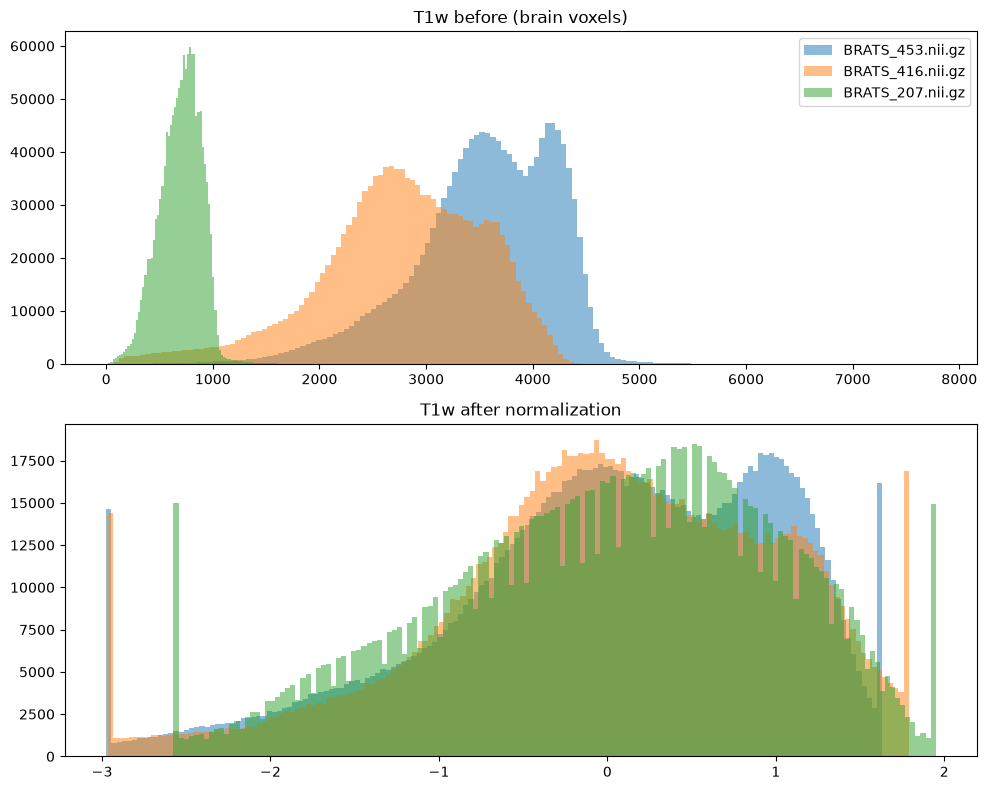

In [4]:
med = df["T1w_mean"].median()
normal = df.loc[(df["T1w_mean"] - med).abs().idxmin(), "case"]
names = ["BRATS_453.nii.gz", "BRATS_416.nii.gz", normal]
print("typical case:", normal)

fig, axes = plt.subplots(2, 1, figsize=(10, 8))
for n in names:
    img, lbl = load_case(*name_to_case[n])
    norm, brain = normalize_case(img)
    axes[0].hist(img[1][brain], bins=150, alpha=0.5, label=n)
    axes[1].hist(norm[1][brain], bins=150, alpha=0.5, label=n)
axes[0].set_title("T1w before (brain voxels)")
axes[1].set_title("T1w after normalization")
axes[0].legend()
plt.tight_layout()
plt.show()

In [7]:
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, CropForegroundd,
    EnsureTyped, MapTransform,
)
from monai.data import PersistentDataset
import torch


class NormalizeBrainD(MapTransform):
    def __init__(self, keys, p_low = 1, p_high = 99):
        super().__init__(keys)
        self.p_low, self.p_high = p_low, p_high

    def __call__(self, data):
        d = dict(data)
        for k in self.key_iterator(data):
            x = np.asarray(d[k], dtype = np.float32)
            brain = (x != 0).any(axis = 0)
            out = np.zeros_like(x)
            for c in range(x.shape[0]):
                v = x[c][brain]
                lo, hi = np.percentile(v, [self.p_low, self.p_high])
                v = np.clip(v, lo, hi)
                out[c][brain] = (v - v.mean()) / (v.std() + 1e-8)
            d[k] = torch.from_numpy(out)
        return d

In [8]:
preprocess = Compose([
    LoadImaged(keys=["image", "label"]),
    EnsureChannelFirstd(keys=["image"], channel_dim=-1),
    EnsureChannelFirstd(keys=["label"], channel_dim="no_channel"),
    CropForegroundd(keys=["image", "label"], source_key="image", margin=4),
    NormalizeBrainD(keys=["image"]),
    EnsureTyped(keys=["image"], dtype=torch.float16),
    EnsureTyped(keys=["label"], dtype=torch.uint8),
])

In [9]:
data = [{"image": str(i), "label": str(l)} for i, l in cases]

sample = data[0]
for t in preprocess.transforms:
    sample = t(sample)
    print(f"{type(t).__name__:22s}",
          "image:", tuple(sample["image"].shape), "|",
          "label:", tuple(sample["label"].shape))

LoadImaged             image: (240, 240, 155, 4) | label: (240, 240, 155)
EnsureChannelFirstd    image: (4, 240, 240, 155) | label: (240, 240, 155)
EnsureChannelFirstd    image: (4, 240, 240, 155) | label: (1, 240, 240, 155)
CropForegroundd        image: (4, 148, 177, 149) | label: (1, 148, 177, 149)
NormalizeBrainD        image: (4, 148, 177, 149) | label: (1, 148, 177, 149)
EnsureTyped            image: (4, 148, 177, 149) | label: (1, 148, 177, 149)
EnsureTyped            image: (4, 148, 177, 149) | label: (1, 148, 177, 149)
